# Interaction Elémentaire

### Préparation de  l'environnement

##### Please `pip install -r requirements.txt` first

##### Fichiers necessaires:
* `TCL_wt1.tsv`: l'experience de protéomique                       
* `tree_ecoli_K12_measured_redis.pik`: Un arbre d'ontologie GO (voir plus bas)
* `uniprot_store_ecoli_K12.pik`: le protéome uniprot d'E.Coli
* Un éventuel fichier JSON structurant les analyses ORA du TP2


## Création d'un scatter plot interactif

### Visualisation des abondances et Pathway pour chaque protéine

Nous allons représenter la relation entre l'abondance des protéines (**Log2 Corrected Abundance Ratio**)  et la précision de la mesure (**LOG10 Adj.P-val**).

In [2]:
import pandas
import numpy as np
# We use notebook ipympl to have interactivity support
%matplotlib ipympl 

import matplotlib.pyplot as plt

## Exemple pour commencer
Observer la cellule suivante qui illustre la construction d'un scatter plot et des améliorations possibles.

###### Creation du scatter plot
[matplotlib.axes.Axes.scatter()](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.axes.Axes.scatter.html) permet d'intialiser le graphique.
Les quatre arguments positionnels suivants peuvent être donnés:
```python
Axes.scatter(x,          # Les coordonnées X des points: Float[]
             y,          # Les coordonnées Y des points: Float[]
             radius,     # Les rayons des points       : Float[] | Float 
             color,      # Les couleurs des points     : ColorSymbol[] | ColorSymbol
             picker=True # Active la gestion événementielle du click, "le picking de points", sur le graphique
            )
```
Bien sûr, seuls les deux premiers sont obligatoires, `radius` et `color` étant dotés de valeurs par défault. Si une seule valeur est passée à `radius` ou `color`, elle sera appliqué uniformément à tous les points. 

###### Modification continue du scatter plot
Mais cette fonction retourne aussi un objet [PathCollection](https://matplotlib.org/3.1.1/api/collections_api.html) qui permet de modifier à posteriori le rendu des points du scatter plot.
###### Interactivité
L'affichage d'une figure via la méthode `fig.canvas.mpl_connect('EVENT_NAME', callbackFunction)` permet d'associer à [un évenement sur la figure](https://matplotlib.org/3.1.1/users/event_handling.html) l'execution d'une fonction (*callbackFunction*). Cette fonction *callback* se voit passer un argument de type *event* qui détaille l'événement (par exemple la position du pointeur). 

A partir de matplotlib 3.5.0, on lui préferera à la fonction *mpl_connect* la fonction [connect_event()](https://matplotlib.org/stable/api/widgets_api.html?highlight=mpl_connect).

</br><span style="color:green; font-weight:bold">$\downarrow$ Illustration ci-dessous $\downarrow$</span>
</br><span style="color:green;"> NB: Pour l'instant nous passons une liste de nombres aléatoires comme argument "couleur" et matplotlib créé pour nous une palette de couleurs. Nous verrons plus tard comment **choisir notre palette de couleurs**. Essayez de clicker et sur la figure et observer le déroulé des fonctions.</span>

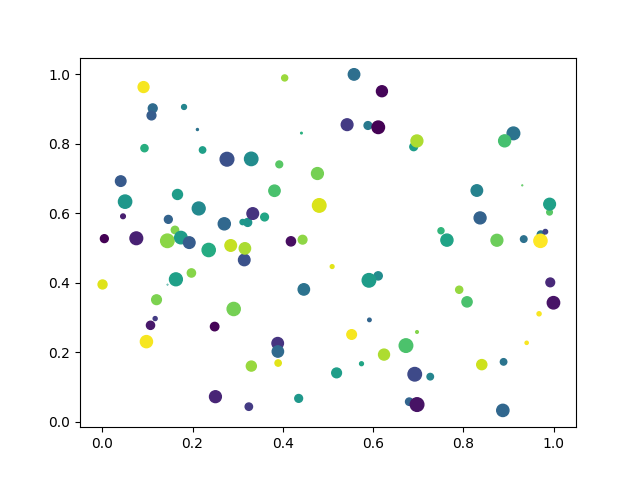

In [4]:
x, y, c, s = np.random.rand(4, 100)
    
def onpick(event):
    """ Error won't show on the graphics and the figure which will remain idle.
        So we capture the error and show its message directly on the graphic
    """

    try :
        ind = event.ind
        tx = str(ind)
        text.set_text(tx)
        path_collection.set_sizes( np.random.rand(100) * 100 )
    except Exception as e:
        dbg_text.set_text( str(e) )
        
        
fig = plt.figure()
ax1 = fig.add_subplot(111)
path_collection = ax1.scatter(x, y, 100*s, c, picker=True)
text = ax1.text(0.5,1.1, "", va="bottom", ha="left")
dbg_text = ax1.text(0.1,1.1, "", color="red", va="bottom", ha="left")

cid = fig.canvas.mpl_connect('pick_event', onpick)

## Exercice1: Volcano plot interactif

<br/><span style="color:firebrick;font-weight:bold">$\rhd$ Lecture des données à partir du TSV 
 comme dans le TP précédent</span>
 <br/><span style="color:firebrick;font-weight:bold">$\rhd$ Dessiner un volcano plot qui affichera via <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.text.html">Axes.text</a> le nom de la protéine cliquée</span>
 
<span style="color:green">NB : Comme illustré ci-dessus, le paramètre event possède un attribut *ind* qui est l'indice de l'élément cliqué.</span>
</br><span style="color:green">$\downarrow$ Vous pouvez faire une figure à deux axes: le premier détenant le scatter-plot et le deuxième axe n'affichant que le nom de la protéine cliquée</span>

## Exercice2:  Deux volcano plot avancés

>Rappels: Le TP2 documente l'utilisation de l'objet *go_tree* pour obtenir toute les protéines du protéome de E.Coli porteuses d'un teme GO particulier.

Dans un premier volcano plot:

* Colorier les protéines des n Pathways les plus représentés dans le namespace GO de votre choix (biological_process, molecular function, cellular component): **utiliser des palettes de couleurs catégorielles**. Pour une protéine, la priorité sera donnée au pathway avec la meilleur p-value.

Dans un nouvelle figure volcano plot, implémenter **une** des fonctionnalités suivantes:

* Colorier d'une même couleur les protéines appartenant au pathway (de meilleure p-value) GO de la protéine clickée
* Faire disparaitre les protéines n'appartenant pas au même pathway (de meilleure p-value) GO que celui de la protéine clickée

<span style="color:green;font-weight:bold">$\downarrow$ Parcourez l'aide ci-dessous avant de choisir$\downarrow$</span>

### <span style="color:green">Rappel et guide: Palettes de couleurs</span>
matplotlib propose une variété de [palettes de couleurs](https://matplotlib.org/stable/tutorials/colors/colormaps.html).
##### Divergentes ou Séquentielles
![caption](figs/cmap1.png)
![caption](figs/cmap2.png)
##### Continues ou Catégorielles
![caption](figs/cmap4.png)
##### Cyclique
![caption](figs/cmap3.png)

<br/><span style="color:firebrick;font-weight:bold">$\rhd$ Quel type de palette choisir pour colorier en fonction:</span>
* <span style="color:firebrick">Des pathways ?</span>
* <span style="color:firebrick">Des pvalues ? </span>

### <span style="color:green">API colormap</span>
###### Charger une palette de couleurs
```python
cmap = plt.get_cmap('Paired')
```

###### Palettes de couleurs catégorielles
Elles proposent des valeurs discrètes organisées en une liste de triplets RGB
###### Connaitre son nombre d'éléments
```python
print(cmap.N)
```
###### Accéder à sa liste de couleurs
```python
print(cmap.colors)
```
###### Exemple
![caption](figs/cmap5.png)

##### Palettes de couleurs quantitatives
Elles proposent des valeurs de couleurs continues.

Il s'agit de fonctions prenant une valeur en entrée et retournant un triplet RGB. Par défault le domaine de cette fonction est $[0, 1]$. L'intervalle est "cyclique", (1.2 donne 0.2, -1.5 donne 0.5, etc).

Dans la pratique on devra donc normaliser les valeurs à colorer, pour qu'elles soient contenues dans l'intervalle $[0, 1]$. Deux questions se posent alors pour définir cette fonction $f$:
* Les bornes min et max de l'intervalle des valeurs à colorer, telles que $f(min) = 0, f(max) = 1$
* L'interpolation pour determiner les valeurs intermédiaires, les plus usuelles étant:
    * Linéaire
    * Logarithmique
    
**Le module [colors](https://matplotlib.org/3.1.1/api/colors_api.html) fournit deux outils suivants**

###### Fonctions de normalisation 
![caption](figs/cmap6.png)
###### Fonctions de couleur
![caption](figs/cmap7.png)

###### Exemples avec la palette HSV
* Colorations avec **normalisation linéaire**, **normalisation logarithmique**, **normalisation logarithmique explicite**
![caption](figs/cmap8.png)

<br/><span style="color:firebrick;font-weight:bold">$\rhd$ Lecture des données à partir du TSV 
 comme dans le TP précédent</span>
 <br/><span style="color:firebrick;font-weight:bold">$\rhd$ Réalisez les calculs ORA grâce à <i>obogo.stastics </i> OU rechargez des données ORA via les fichiers  <i>data/ora/*.json</i></span>

 <br/><span style="color:firebrick;font-weight:bold">$\rhd$ Construction du premier volcano-plot avancé choisi </span>

 <br/><span style="color:firebrick;font-weight:bold">$\rhd$ Construction du deuxième volcano-plot avancé choisi </span>

In [6]:


#go_scores_mf

## pandas read-in "Accession" , "Log2 Corrected Abundance Ratio" and "LOG10 Adj.P-val".
# drop #!VALEUR n/a values



[[7.659089914004261e-10,
  'porin activity',
  'GO:0015288',
  ['P0A910', 'P06996', 'P06129', 'P02930', 'P02931', 'P0A927', 'P10384']],
 [1.0952537732206579e-08,
  'channel activity',
  'GO:0015267',
  ['P0A910',
   'P06996',
   'P06129',
   'P02930',
   'P02931',
   'P0A927',
   'P10384',
   'P10384',
   'P06129',
   'P02930',
   'P02931']],
 [8.515957710139766e-05,
  'ion channel activity',
  'GO:0005216',
  ['P06129', 'P02930', 'P02931']],
 [8.515957710139766e-05,
  'protein domain specific binding',
  'GO:0019904',
  ['P06971', 'P06129', 'P02931']],
 [9.317549123770794e-05,
  'protein N-terminus binding',
  'GO:0047485',
  ['P02930', 'P02931']],
 [0.00014577300306363501,
  'signaling receptor activity',
  'GO:0038023',
  ['P13036', 'P06971', 'P75780']],
 [0.0031004517807219903,
  'transmembrane transporter activity',
  'GO:0022857',
  ['P02931',
   'P13036',
   'P10384',
   'P06129',
   'P02930',
   'P02931',
   'P0A927',
   'P0A910',
   'P06996',
   'P06129',
   'P02930',
   'P029

In [15]:
go_scores_mf[0]

[7.659089914004261e-10,
 'porin activity',
 'GO:0015288',
 ['P0A910', 'P06996', 'P06129', 'P02930', 'P02931', 'P0A927', 'P10384']]

In [23]:
import json 
f_go = "../data/ora/molecular_function.json"
with open(f_go, 'r', encoding='utf-8') as file:
    go_scores_mf = json.load(file)
#### Rich representation of a go_term data object
class RichGoTermList():
    # An item is of the shape
    # [7.659089914004261e-10,
    # 'porin activity',
    # 'GO:0015288',
    # ['P0A910', 'P06996', 'P06129', 'P02930', 'P02931', 'P0A927', 'P10384']]
    def __init__(self, go_terms_list):
        self.data = go_terms_list
        
    def _repr_html_(self):
        htmlString = "<table><thead><tr><td>Go term</td><td>Go id</td><td>p valeur</td><td>nb prot</td></tr></thead>"
        for go_score in self.data:
            htmlString += f"<tr><td><a href='www.ens-lyon.fr'>{go_score[1]}</a></td>"
            htmlString += f"<td>{go_score[2]}</td>"
            htmlString += f"<td>{go_score[0]}</td>"
            htmlString += f"<td>{len(go_score[3])}</td>"
            htmlString += "</tr>"
        htmlString += "</table>"
        return htmlString

rgtl = RichGoTermList(go_scores_mf)
rgtl

Go term,Go id,p valeur,nb prot
porin activity,GO:0015288,7.659089914004261e-10,7
channel activity,GO:0015267,1.0952537732206579e-08,11
ion channel activity,GO:0005216,8.515957710139766e-05,3
protein domain specific binding,GO:0019904,8.515957710139766e-05,3
protein N-terminus binding,GO:0047485,9.317549123770794e-05,2
signaling receptor activity,GO:0038023,0.00014577300306363501,3
transmembrane transporter activity,GO:0022857,0.0031004517807219903,17
transporter activity,GO:0005215,0.003271943059100669,17
inorganic molecular entity transmembrane transporter activity,GO:0015318,0.004090563076868543,5
ion transmembrane transporter activity,GO:0015075,0.005502262072619408,6


In [17]:
# Find the best GO term of a given protein
import json 
f_go = "../data/ora/molecular_function.json"
with open(f_go, 'r', encoding='utf-8') as file:
    go_scores_mf = json.load(file)
#### Rich representation of a go_term data object
class RichGoTermList():
    # An item is of the shape
    # [7.659089914004261e-10,
    # 'porin activity',
    # 'GO:0015288',
    # ['P0A910', 'P06996', 'P06129', 'P02930', 'P02931', 'P0A927', 'P10384']]
    def __init__(self, go_terms_list):
        self.data = go_terms_list
        
    def _repr_html_(self):
        htmlString = "<table><thead><tr><td>Abscisse</td><td>Ordonnée</td><td>Cote</td></tr></thead>"
        htmlString += f"<tbody><tr><td>{self.x}</td><td>{self.y}</td><td>{self.z}</td></tr></tbody></table>"
        return htmlString

rgtl = RichGoTermList(go_scores_mf)




#######
def get_best_term(acc:str)-> str|None:
    # GO tree aka "go_scores_mf" MUST BE ALREADY LOADED
    # terms are ordered by ascendant p_value
    # for a given protein ac, the 1st matching term is the "best" one
    for term in go_scores_mf:
        proteins = term[-1]
        if acc in proteins:
            return term[1]
    return None
get_best_term("P75780")

7.659089914004261e-10


'signaling receptor activity'

In [1]:
# Try to retrieve all proteins carrying any go term (eg: "GO:0015288")
# Load all protein annotations, NOT THE ORA ANALYSIS
import obogo
import pickle
go_tree = pickle.load( open("../data/obogo/tree_ecoli_K12_measured_redis.pik", "rb" ) )

def get_acc_of_go(go_id:str)->list[str]:
    # Look up in go tree for go_id related informations
    # go_tree data structure MUST ALREADY BE LOADED
    uniprot_from_go = go_tree.get_proteins(go_id)
    # cherry-pick the accession from the uniprot obj list
    return [uniprot.id for uniprot in uniprot_from_go]

get_acc_of_go("GO:0015288")

c_vec = [  'blue' if acc in go_results['prot_list'] else 'red'  for acc in all_ac_list ]

NameError: name 'all_ac_list' is not defined

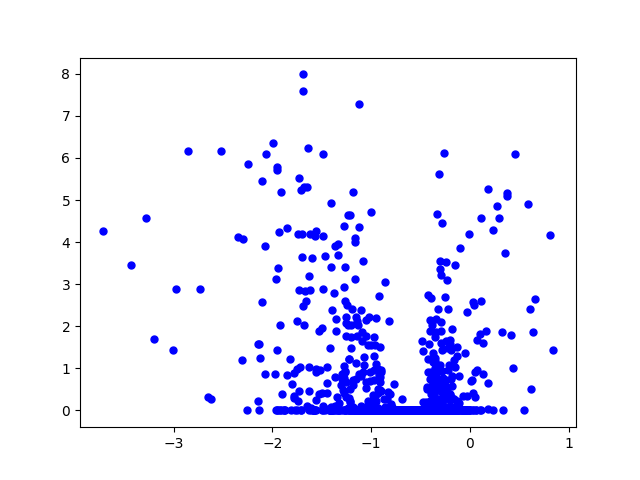

In [36]:
import pandas
ms_df = pandas.read_csv("../data/TCL_wt1.tsv", sep = "\t", na_values=["#VALEUR!"])
ms_df = ms_df.dropna()
fc    = ms_df["Log2 Corrected Abundance Ratio"].tolist()
adj_p = ms_df["LOG10 Adj.P-val"].tolist()
acc   = ms_df["Accession"].tolist()

def onpick(event):
    """ Error won't show on the graphics and the figure which will remain idle.
        So we capture the error and show its message directly on the graphic
    """
    try :
        ind = event.ind
        if len(ind) > 0:
            one_ind = ind[0]
            one_acc = acc[one_ind]
            best_go_term = get_best_term(one_acc)
            if best_go_term is None:
                best_go_term = 'None :(('
            text.set_text(str(one_acc) + "//" + best_go_term)
      #  path_collection.set_sizes( np.random.rand(100) * 100 )
    except Exception as e:
        dbg_text.set_text( str(e) )

fig = plt.figure()
ax1 = fig.add_subplot(111)
path_collection = ax1.scatter(fc, adj_p, s=25, c='blue', picker=True)
text = ax1.text(-1.5,9, "", va="bottom", ha="left")
dbg_text = ax1.text(0.1,1.1, "", color="red", va="bottom", ha="left")

cid = fig.canvas.mpl_connect('pick_event', onpick)

[-3.721334942,
 -3.429568818,
 -3.284695189,
 -3.204276506,
 -3.009460329,
 -2.979403095,
 -2.858216749,
 -2.733825887,
 -2.6485786,
 -2.625119627,
 -2.518620006,
 -2.345696261,
 -2.312529397,
 -2.303191532,
 -2.261903324,
 -2.248399059,
 -2.14468771,
 -2.14468771,
 -2.140524085,
 -2.136372442,
 -2.128104826,
 -2.103582507,
 -2.103582507,
 -2.0754902,
 -2.0754902,
 -2.067563284,
 -1.994353437,
 -1.979403095,
 -1.96829114,
 -1.964606093,
 -1.957264118,
 -1.953607095,
 -1.953607095,
 -1.949959318,
 -1.939071001,
 -1.939071001,
 -1.931857511,
 -1.924679909,
 -1.921104455,
 -1.91398002,
 -1.910430953,
 -1.899835838,
 -1.882348411,
 -1.878876219,
 -1.875412364,
 -1.854802084,
 -1.851395483,
 -1.821092723,
 -1.814444347,
 -1.797956224,
 -1.784900071,
 -1.781654412,
 -1.778416038,
 -1.775184916,
 -1.755948698,
 -1.749593202,
 -1.746425923,
 -1.740112149,
 -1.736965594,
 -1.733825887,
 -1.730692997,
 -1.727566896,
 -1.718229032,
 -1.712037198,
 -1.708951218,
 -1.708951218,
 -1.702798991,
 -1.6

In [5]:
def score_ora_tree():
    for i in range(0,10):
        yield i



In [10]:
generator_stuff = score_ora_tree()

list_stuff      = list( score_ora_tree() )

In [11]:
list_stuff[4]

4